# Bab 2 – Alur Kerja Sebelum Modeling dan Preprocessing Data

## Ringkasan Bab
Kualitas model dibatasi oleh kualitas datanya. Bab ini membahas alur kerja sebelum modeling: bagaimana data mentah
merugikan model, cara mengenali masalah umum pada data, **imputasi nilai hilang**, **scaling**,
**encoding variabel kategorikal**, penyusunan semuanya dalam **pipeline** dengan `ColumnTransformer`, dan **feature engineering**.
Bab ditutup dengan latihan praktik.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder,
                                   PolynomialFeatures, KBinsDiscretizer, FunctionTransformer)
from sklearn.linear_model import LogisticRegression
rng = np.random.default_rng(42)

## 1. Dampak Data Mentah terhadap Performa Model
Data mentah biasanya mengandung nilai hilang, outlier, fitur dengan skala berbeda, kategori berupa teks, dan data duplikat.
Banyak algoritma (model linear, SVM, KNN, neural network) **peka terhadap skala**, dan hampir semua model scikit-learn
membutuhkan input **numerik tanpa NaN** (kecuali `HistGradientBoosting*` berbasis pohon).
Untuk demonstrasi, kita buat dataset "churn pelanggan" sintetis yang sengaja dibuat berantakan.

In [2]:
n = 1000
df = pd.DataFrame({
    "age": rng.integers(18, 70, n).astype(float),
    "income": rng.lognormal(10.5, 0.6, n),
    "tenure_months": rng.integers(1, 72, n).astype(float),
    "plan": rng.choice(["basic", "standard", "premium"], n, p=[.5, .3, .2]),
    "city": rng.choice(["Jakarta", "Bandung", "Surabaya", "Medan"], n),
})
logit = -2 + 0.00002*df.income - 0.03*df.tenure_months + (df.plan == "basic")*0.8
df["churn"] = (rng.random(n) < 1/(1+np.exp(-logit))).astype(int)

# inject problems: missing values, duplicates, outliers
df.loc[rng.choice(n, 80, replace=False), "age"] = np.nan
df.loc[rng.choice(n, 60, replace=False), "income"] = np.nan
df.loc[rng.choice(n, 50, replace=False), "plan"] = np.nan
df.loc[rng.choice(n, 5, replace=False), "income"] *= 50
df = pd.concat([df, df.sample(15, random_state=1)], ignore_index=True)
df.head()

,age,income,tenure_months,plan,city,churn
0,22.0,85813.250129,24.0,basic,Bandung,0
1,NaN,38365.431313,38.0,basic,Surabaya,1
2,52.0,51455.171805,14.0,basic,Surabaya,0
3,40.0,35099.075966,63.0,basic,Bandung,0
4,40.0,32785.953356,52.0,basic,Jakarta,0


## 2. Masalah Umum pada Data
Daftar yang perlu diperiksa: **nilai hilang**, **duplikat**, **outlier**, **tipe data atau label yang tidak konsisten**,
**ketidakseimbangan kelas**, **perbedaan skala**, dan **kategori dengan kardinalitas tinggi**.
Data selalu perlu diperiksa dulu sebelum dipakai untuk modeling.

In [3]:
print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicated rows:", df.duplicated().sum())
print("\nClass balance:\n", df.churn.value_counts(normalize=True).round(3))
print(df.describe().round(1))

Shape: (1015, 6)

Missing values per column:
 age              81
income           60
tenure_months     0
plan             50
city              0
churn             0
dtype: int64

Duplicated rows: 15

Class balance:
 churn
0    0.825
1    0.175
Name: proportion, dtype: float64
         age     income  tenure_months   churn
count  934.0      955.0         1015.0  1015.0
mean    43.5    52468.3           35.9     0.2
std     15.0   142321.2           20.3     0.4
min     18.0     6132.0            1.0     0.0
25%     30.0    23676.4           18.0     0.0
50%     44.0    36048.1           35.0     0.0
75%     56.8    52756.2           54.0     0.0
max     69.0  2437498.9           71.0     1.0


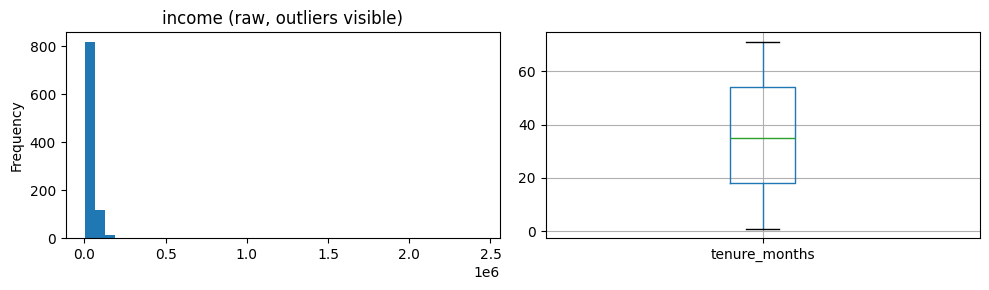

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
df.income.dropna().plot.hist(bins=40, ax=ax[0], title="income (raw, outliers visible)")
df.boxplot(column="tenure_months", ax=ax[1]); plt.tight_layout(); plt.show()

## 3. Membersihkan dan Menyiapkan Data
Hapus baris yang duplikat persis, lalu pisahkan fitur dari target. Pembagian data latih dan uji dilakukan **sebelum**
menghitung statistik apa pun (rata-rata, median, daftar kategori) supaya tidak terjadi kebocoran data.

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
X, y = df.drop(columns="churn"), df["churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(750, 5) (250, 5)


## 4. Menangani Data yang Hilang
Jenis data hilang: **MCAR** (hilang murni acak), **MAR** (hilangnya bergantung pada data lain yang teramati), dan
**MNAR** (hilangnya bergantung pada nilai itu sendiri).

Cara penanganan: membuang baris atau kolom (informasi berkurang) · **SimpleImputer** (mean/median/modus/konstanta) ·
**KNNImputer** (rata-rata dari tetangga terdekat) · **IterativeImputer** (memprediksi tiap fitur dari fitur lain) ·
`add_indicator=True` (menambah kolom penanda "dulunya kosong", berguna untuk kasus MNAR).

In [6]:
num_cols = ["age", "income", "tenure_months"]
for name, imp in [("median", SimpleImputer(strategy="median")),
                  ("knn(k=5)", KNNImputer(n_neighbors=5)),
                  ("median+indicator", SimpleImputer(strategy="median", add_indicator=True))]:
    out = imp.fit_transform(X_train[num_cols])
    print(f"{name:18s} output shape {out.shape}, NaNs left: {np.isnan(out).sum()}")

median             output shape (750, 3), NaNs left: 0
knn(k=5)           output shape (750, 3), NaNs left: 0
median+indicator   output shape (750, 5), NaNs left: 0


## 5. Teknik Scaling
| Scaler | Rumus | Dipakai saat |
|---|---|---|
| `StandardScaler` | (x − μ)/σ | fitur kurang lebih berdistribusi normal |
| `MinMaxScaler` | (x − min)/(max − min) | butuh rentang tetap [0,1] |
| `RobustScaler` | (x − median)/IQR | ada **outlier** |
| `PowerTransformer`/log | mengurangi kemiringan | data sangat miring (misalnya pendapatan) |

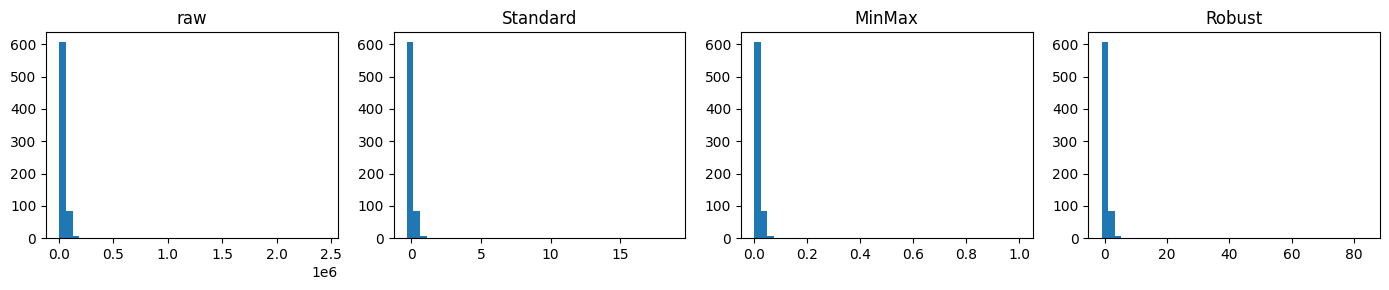

In [7]:
inc = X_train[["income"]].dropna()
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, (t, d) in zip(ax, {"raw": inc, "Standard": StandardScaler().fit_transform(inc),
                          "MinMax": MinMaxScaler().fit_transform(inc),
                          "Robust": RobustScaler().fit_transform(inc)}.items()):
    a.hist(d, bins=40); a.set_title(t)
plt.tight_layout(); plt.show()

## 6. Encoding Variabel Kategorikal
* **OneHotEncoder** untuk kategori nominal (tanpa urutan). Setiap kategori menjadi satu kolom biner. Gunakan `handle_unknown="ignore"`.
* **OrdinalEncoder** untuk kategori yang berurutan (basic < standard < premium). Urutannya ditentukan lewat `categories=[[...]]`.
* **Target/Frequency encoding** untuk kolom dengan banyak kategori unik (`TargetEncoder` tersedia di versi terbaru).

In [8]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
print(ohe.fit_transform(X_train[["city"]])[:3], ohe.get_feature_names_out())
ordc = OrdinalEncoder(categories=[["basic", "standard", "premium"]], handle_unknown="use_encoded_value", unknown_value=-1)
print(ordc.fit_transform(X_train[["plan"]].fillna("basic"))[:5].ravel())

[[0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [0. 0. 1. 0.]] ['city_Bandung' 'city_Jakarta' 'city_Medan' 'city_Surabaya']
[1. 2. 2. 0. 0.]


## 7. Pengenalan Pipeline
`ColumnTransformer` menerapkan preprocessing yang berbeda untuk kolom yang berbeda. Ketika dibungkus `Pipeline` bersama
model, seluruh alur hanya dilatih pada fold latih, sehingga **tidak ada kebocoran data** dan hasilnya mudah diulang.

In [9]:
num_pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", RobustScaler())])
plan_pipe = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ord", OrdinalEncoder(categories=[["basic", "standard", "premium"]]))])
city_pipe = OneHotEncoder(handle_unknown="ignore")

pre = ColumnTransformer([("num", num_pipe, num_cols), ("plan", plan_pipe, ["plan"]), ("city", city_pipe, ["city"])])
model = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)
print("Test accuracy:", round(model.score(X_test, y_test), 3))
model

Test accuracy: 0.824


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('plan', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contain

## 8. Feature Engineering
Membuat fitur baru yang lebih informatif dari fitur yang ada: **suku polinomial/interaksi**, **binning** (`KBinsDiscretizer`),
**transformasi log**, **rasio**, dan fitur berbasis pengetahuan domain. Logika kustom dibungkus dengan `FunctionTransformer`.

In [10]:
def add_features(d):
    d = d.copy()
    d["income_per_tenure"] = d["income"] / (d["tenure_months"] + 1)
    return d

fe = Pipeline([("fe", FunctionTransformer(add_features)), ("pre", ColumnTransformer([
        ("num", num_pipe, num_cols + ["income_per_tenure"]),
        ("plan", plan_pipe, ["plan"]), ("city", city_pipe, ["city"])]))])
poly = PolynomialFeatures(degree=2, include_bias=False)
print("Poly example:", poly.fit_transform([[2, 3]]), poly.get_feature_names_out(["a", "b"]))
print("Bins:", KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile").fit_transform(X_train[["tenure_months"]])[:5].ravel())
model_fe = Pipeline([("fe", fe), ("clf", LogisticRegression(max_iter=1000))])
for nm, m in [("baseline", model), ("with engineered feature", model_fe)]:
    print(f"{nm:25s} CV acc = {cross_val_score(m, X_train, y_train, cv=5).mean():.3f}")

Poly example: [[2. 3. 4. 6. 9.]] ['a' 'b' 'a^2' 'a b' 'b^2']
Bins: [1. 2. 1. 1. 1.]


baseline                  CV acc = 0.821


/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_discretization.py:304: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


with engineered feature   CV acc = 0.823


## 9. Latihan Praktik Preprocessing
Kita bandingkan dua pendekatan dengan cross-validation: **membuang baris yang mengandung NaN** dan **pipeline lengkap**.
(Tanpa preprocessing sama sekali tidak mungkin, karena model tidak menerima NaN.)

In [11]:
dropna_idx = X_train.dropna().index
Xd, yd = X_train.loc[dropna_idx], y_train.loc[dropna_idx]
drop_model = Pipeline([("pre", ColumnTransformer([("n", StandardScaler(), num_cols),
                       ("c", OneHotEncoder(handle_unknown="ignore"), ["plan", "city"])])),
                       ("clf", LogisticRegression(max_iter=1000))])
print(f"Rows kept after dropna: {len(Xd)}/{len(X_train)}")
print("Drop-NaN  CV acc:", round(cross_val_score(drop_model, Xd, yd, cv=5).mean(), 3))
print("Full pipe CV acc:", round(cross_val_score(model, X_train, y_train, cv=5).mean(), 3))

Rows kept after dropna: 626/750


Drop-NaN  CV acc: 0.827
Full pipe CV acc: 0.821


**Kesimpulan:** pipeline mempertahankan semua baris data, mencegah kebocoran, dan menghasilkan alur kerja yang bisa diulang.
Membuang baris yang kosong membuang data yang sebenarnya masih berguna.